In [1]:
import sys
import logging
from pathlib import Path
import pandas as pd
import numpy as np
import json
from tqdm.auto import tqdm
import torch
from transformers import AutoModelForCausalLM, AutoTokenizer, BitsAndBytesConfig
from datetime import datetime
import matplotlib.pyplot as plt
import seaborn as sns

# Add src to path
sys.path.insert(0, str(Path.cwd().parent / 'src'))

from src.data.database import EntityDatabase

# Configure logging
logging.basicConfig(
    level=logging.INFO,
    format='%(asctime)s - %(name)s - %(levelname)s - %(message)s'
)
logger = logging.getLogger(__name__)

# Seaborn style
sns.set_style('whitegrid')
plt.rcParams['figure.dpi'] = 100

## 1. Configuration

In [2]:
# Paths
DB_PATH = Path('../data/entities.db')
RESULTS_PATH = Path('../data/experiment/llm_results.jsonl')
CHECKPOINT_PATH = Path('../data/experiment/llm_checkpoint.json')

# Model configuration
MODEL_NAME = "mistralai/Mistral-7B-Instruct-v0.2"
BATCH_SIZE = 32
MAX_LENGTH = 512

# Create output directory
RESULTS_PATH.parent.mkdir(parents=True, exist_ok=True)

print(f"Configuration:")
print(f"  Model: {MODEL_NAME}")
print(f"  Batch size: {BATCH_SIZE}")
print(f"  Results: {RESULTS_PATH}")
print(f"  Device: {'cuda' if torch.cuda.is_available() else 'cpu'}")
if torch.cuda.is_available():
    print(f"  GPU: {torch.cuda.get_device_name(0)}")
    print(f"  VRAM: {torch.cuda.get_device_properties(0).total_memory / 1024**3:.1f} GB")

Configuration:
  Model: mistralai/Mistral-7B-Instruct-v0.2
  Batch size: 32
  Results: ../data/experiment/llm_results.jsonl
  Device: cuda
  GPU: NVIDIA GeForce RTX 5080
  VRAM: 15.5 GB


## 2. Load Database and Questions

In [3]:
# Initialize database
db = EntityDatabase(DB_PATH)

print(f"✓ Connected to database: {DB_PATH}")

2026-01-07 02:17:20,234 - src.data.database - INFO - Database initialized at ../data/entities.db


✓ Connected to database: ../data/entities.db


In [4]:
# Load all questions
all_questions = db.get_all_questions()
questions_df = pd.DataFrame(all_questions)

print(f"Total questions in database: {len(questions_df):,}")
print(f"Unique entities: {questions_df['entity_id'].nunique():,}")

print(f"\nBreakdown:")
print(f"  Languages: {questions_df['language'].value_counts().to_dict()}")
print(f"  Question types: {questions_df['question_type'].value_counts().to_dict()}")

Total questions in database: 205,098
Unique entities: 23,007

Breakdown:
  Languages: {'en': 68366, 'fr': 68366, 'ar': 68366}
  Question types: {'birth_place': 69021, 'birth_date': 69021, 'nationality': 67056}


## 3. Resume: Load Existing Results

In [5]:
# Load existing results if any
completed_question_ids = set()
existing_results = []

if RESULTS_PATH.exists():
    print(f"Found existing results file: {RESULTS_PATH}")
    with open(RESULTS_PATH, 'r', encoding='utf-8') as f:
        for line in f:
            if line.strip():
                result = json.loads(line)
                completed_question_ids.add(result['question_id'])
                existing_results.append(result)

    print(f"  Loaded {len(completed_question_ids):,} completed questions")
    print(f"  Will resume from question {len(completed_question_ids) + 1}")
else:
    print(f"No existing results found. Starting fresh.")

# Filter out completed questions
remaining_questions_df = questions_df[~questions_df['id'].isin(completed_question_ids)].copy()

print(f"\nProgress:")
print(f"  Completed: {len(completed_question_ids):,}")
print(f"  Remaining: {len(remaining_questions_df):,}")
print(f"  Total: {len(questions_df):,}")
print(f"  Progress: {len(completed_question_ids)/len(questions_df)*100:.1f}%")

No existing results found. Starting fresh.

Progress:
  Completed: 0
  Remaining: 205,098
  Total: 205,098
  Progress: 0.0%


## 4. Load LLM Model

In [6]:
class MultipleChoiceLogitsProcessor:
    """Constrains model to only output A, B, C, or D"""

    def __init__(self, tokenizer):
        self.tokenizer = tokenizer
        # Get token IDs for A, B, C, D
        self.valid_tokens = [
            tokenizer.encode("A", add_special_tokens=False)[0],
            tokenizer.encode("B", add_special_tokens=False)[0],
            tokenizer.encode("C", add_special_tokens=False)[0],
            tokenizer.encode("D", add_special_tokens=False)[0],
        ]
        logger.info(
            f"Valid answer tokens: A={self.valid_tokens[0]}, B={self.valid_tokens[1]}, "
            f"C={self.valid_tokens[2]}, D={self.valid_tokens[3]}"
        )

    def get_constrained_probabilities(self, logits):
        """
        Extract probabilities for A/B/C/D only, normalized to sum to 1.0

        Args:
            logits: Model logits for next token [batch_size, vocab_size] or [vocab_size]

        Returns:
            Dict with probabilities for each option (or list of dicts for batch)
        """
        # Handle both single and batch inputs
        is_batch = len(logits.shape) > 1

        if not is_batch:
            logits = logits.unsqueeze(0)

        # Create mask: set all tokens to -inf except A/B/C/D
        mask = torch.full_like(logits, float('-inf'))
        mask[:, self.valid_tokens] = 0

        # Apply mask and get probabilities
        constrained_logits = logits + mask
        probs = torch.softmax(constrained_logits, dim=-1)

        # Extract probabilities for A/B/C/D
        results = []
        for i in range(probs.shape[0]):
            results.append({
                'A': probs[i, self.valid_tokens[0]].item(),
                'B': probs[i, self.valid_tokens[1]].item(),
                'C': probs[i, self.valid_tokens[2]].item(),
                'D': probs[i, self.valid_tokens[3]].item(),
            })

        return results if is_batch or len(results) > 1 else results[0]

In [7]:
def load_model_and_tokenizer(model_name: str = MODEL_NAME):
    """Load quantized model for efficient inference"""
    logger.info(f"Loading model: {model_name}")

    # Create quantization config
    quantization_config = BitsAndBytesConfig(
        load_in_4bit=True,
        bnb_4bit_quant_type="nf4",
        bnb_4bit_compute_dtype=torch.bfloat16,
        bnb_4bit_use_double_quant=True,
    )

    # Load model
    model = AutoModelForCausalLM.from_pretrained(
        model_name,
        quantization_config=quantization_config,
        device_map="auto",
        torch_dtype=torch.bfloat16,
        low_cpu_mem_usage=True,
    )

    tokenizer = AutoTokenizer.from_pretrained(model_name)
    tokenizer.pad_token = tokenizer.eos_token
    tokenizer.padding_side = "left"  # Important for batch processing

    model.eval()

    logger.info(f"✓ Model loaded on device: {model.device}")
    logger.info(f"✓ Model dtype: {model.dtype}")

    return model, tokenizer

In [8]:
# Load model
print("Loading model... (this may take 1-2 minutes)")
model, tokenizer = load_model_and_tokenizer()
processor = MultipleChoiceLogitsProcessor(tokenizer)

print("\n✓ Model ready for inference!")

2026-01-07 02:17:36,795 - __main__ - INFO - Loading model: mistralai/Mistral-7B-Instruct-v0.2


Loading model... (this may take 1-2 minutes)


`torch_dtype` is deprecated! Use `dtype` instead!
2026-01-07 02:17:38,283 - accelerate.utils.modeling - INFO - We will use 90% of the memory on device 0 for storing the model, and 10% for the buffer to avoid OOM. You can set `max_memory` in to a higher value to use more memory (at your own risk).


Loading checkpoint shards:   0%|          | 0/3 [00:00<?, ?it/s]

2026-01-07 02:17:58,031 - __main__ - INFO - ✓ Model loaded on device: cuda:0
2026-01-07 02:17:58,031 - __main__ - INFO - ✓ Model dtype: torch.bfloat16
2026-01-07 02:17:58,033 - __main__ - INFO - Valid answer tokens: A=330, B=365, C=334, D=384



✓ Model ready for inference!


## 5. Prompt Formatting

In [9]:
def format_question_prompt(question_data: dict, language: str) -> str:
    """
    Format multiple-choice question with Mistral instruction format

    Args:
        question_data: Question row from database
        language: Language code (en/fr/ar)

    Returns:
        Formatted prompt string with [INST] tags
    """
    # Parse options - stored as list of dicts
    options_list = json.loads(question_data['options'])
    options = {opt['letter']: opt['text'] for opt in options_list}

    # Build prompt based on language
    if language == 'en':
        content = f"""Question: {question_data['question_text']}

A) {options['A']}
B) {options['B']}
C) {options['C']}
D) {options['D']}

Answer:"""
    elif language == 'fr':
        content = f"""Question: {question_data['question_text']}

A) {options['A']}
B) {options['B']}
C) {options['C']}
D) {options['D']}

Réponse:"""
    elif language == 'ar':
        content = f"""السؤال: {question_data['question_text']}

أ) {options['A']}
ب) {options['B']}
ج) {options['C']}
د) {options['D']}

الإجابة:"""
    else:
        raise ValueError(f"Unsupported language: {language}")

    # Wrap with Mistral instruction format
    return f"[INST] {content} [/INST]"


# Test formatting
if len(remaining_questions_df) > 0:
    sample = remaining_questions_df.iloc[0]
    sample_prompt = format_question_prompt(sample, sample['language'])
    print("Sample prompt:")
    print("=" * 80)
    print(sample_prompt)
    print("=" * 80)

Sample prompt:
[INST] Question: Where was Dwayne Johnson born?

A) Bouaké
B) Hayward
C) Duisburg
D) Bremen

Answer: [/INST]


## 6. Batch Evaluation Function

In [10]:
def evaluate_batch(questions_batch, model, tokenizer, processor):
    """
    Evaluate a batch of questions

    Args:
        questions_batch: List of question dicts
        model: LLM model
        tokenizer: Tokenizer
        processor: MultipleChoiceLogitsProcessor

    Returns:
        List of result dicts
    """
    # Format prompts
    prompts = [format_question_prompt(q, q['language']) for q in questions_batch]

    # Tokenize batch
    inputs = tokenizer(
        prompts,
        return_tensors="pt",
        padding=True,
        truncation=True,
        max_length=MAX_LENGTH
    )
    inputs = {k: v.to(model.device) for k, v in inputs.items()}

    # Get model output
    with torch.no_grad():
        outputs = model(**inputs)

        # Get logits for the last position (where answer would go)
        # Shape: [batch_size, vocab_size]
        next_token_logits = outputs.logits[:, -1, :]

        # Get constrained probabilities for each question
        probs_list = processor.get_constrained_probabilities(next_token_logits)

    # Build results
    results = []
    for i, (question, probs) in enumerate(zip(questions_batch, probs_list)):
        predicted_answer = max(probs, key=probs.get)
        is_correct = predicted_answer == question['correct_answer']

        results.append({
            'question_id': int(question['id']),
            'entity_id': int(question['entity_id']),
            'question_type': question['question_type'],
            'language': question['language'],
            'correct_answer': question['correct_answer'],
            'predicted_answer': predicted_answer,
            'is_correct': is_correct,
            'probabilities': probs,
            'confidence': probs[predicted_answer],
            'correct_prob': probs[question['correct_answer']],
            'timestamp': datetime.now().isoformat()
        })

    return results

## 7. Main Evaluation Loop with Resume

In [11]:
# Open results file in append mode
results_file = open(RESULTS_PATH, 'a', encoding='utf-8')

# Statistics tracking
stats = {
    'total_processed': len(completed_question_ids),
    'total_correct': sum(1 for r in existing_results if r.get('is_correct', False)),
    'batch_errors': 0
}

print(f"Starting evaluation of {len(remaining_questions_df):,} questions...")
print(f"Batch size: {BATCH_SIZE}")
print(f"")

try:
    # Process in batches
    questions_list = remaining_questions_df.to_dict('records')

    with tqdm(total=len(questions_list), initial=0, desc="Evaluating") as pbar:
        for i in range(0, len(questions_list), BATCH_SIZE):
            batch = questions_list[i:i+BATCH_SIZE]

            try:
                # Evaluate batch
                batch_results = evaluate_batch(batch, model, tokenizer, processor)

                # Save results immediately
                for result in batch_results:
                    results_file.write(json.dumps(result, ensure_ascii=False) + '\n')
                    stats['total_processed'] += 1
                    if result['is_correct']:
                        stats['total_correct'] += 1

                results_file.flush()  # Ensure written to disk

                # Update progress bar
                pbar.update(len(batch))

                # Update progress bar description with stats
                accuracy = stats['total_correct'] / stats['total_processed'] * 100
                pbar.set_postfix({
                    'acc': f"{accuracy:.1f}%",
                    'errors': stats['batch_errors']
                })

            except Exception as e:
                logger.error(f"Error processing batch {i//BATCH_SIZE}: {e}")
                logger.info("Falling back to single-question processing for this batch...")
                stats['batch_errors'] += 1

                # Process questions one by one
                for question in batch:
                    try:
                        single_result = evaluate_batch([question], model, tokenizer, processor)
                        result = single_result[0]
                        results_file.write(json.dumps(result, ensure_ascii=False) + '\n')
                        stats['total_processed'] += 1
                        if result['is_correct']:
                            stats['total_correct'] += 1
                        pbar.update(1)
                    except Exception as e2:
                        logger.error(f"Failed to process question {question['id']}: {e2}")
                        pbar.update(1)

                results_file.flush()

            # Periodic checkpoint every 1000 questions
            if (i + BATCH_SIZE) % 1000 == 0:
                checkpoint = {
                    'processed': stats['total_processed'],
                    'correct': stats['total_correct'],
                    'accuracy': stats['total_correct'] / stats['total_processed'] * 100,
                    'timestamp': datetime.now().isoformat()
                }
                with open(CHECKPOINT_PATH, 'w') as f:
                    json.dump(checkpoint, f, indent=2)

finally:
    results_file.close()

print("\n" + "="*80)
print("EVALUATION COMPLETE")
print("="*80)
print(f"Total processed: {stats['total_processed']:,}")
print(f"Total correct: {stats['total_correct']:,}")
print(f"Overall accuracy: {stats['total_correct']/stats['total_processed']*100:.2f}%")
print(f"Batch errors: {stats['batch_errors']}")
print(f"\nResults saved to: {RESULTS_PATH}")

Starting evaluation of 205,098 questions...
Batch size: 32



Evaluating:   0%|          | 0/205098 [00:00<?, ?it/s]


EVALUATION COMPLETE
Total processed: 205,098
Total correct: 98,678
Overall accuracy: 48.11%
Batch errors: 0

Results saved to: ../data/experiment/llm_results.jsonl


## 8. Load and Analyze Results

In [12]:
# Load all results
results = []
with open(RESULTS_PATH, 'r', encoding='utf-8') as f:
    for line in f:
        if line.strip():
            results.append(json.loads(line))

results_df = pd.DataFrame(results)

print(f"Loaded {len(results_df):,} evaluation results")
print(f"\nColumns: {list(results_df.columns)}")
results_df.head()

Loaded 205,098 evaluation results

Columns: ['question_id', 'entity_id', 'question_type', 'language', 'correct_answer', 'predicted_answer', 'is_correct', 'probabilities', 'confidence', 'correct_prob', 'timestamp']


,question_id,entity_id,question_type,language,correct_answer,predicted_answer,is_correct,probabilities,confidence,correct_prob,timestamp
0,254777,1,birth_place,en,B,D,False,"{'A': 8.487701416015625e-05, 'B': 4.8398971557...",1.000000,0.000048,2026-01-07T02:18:21.923932
1,254778,1,birth_place,fr,B,D,False,"{'A': 0.056640625, 'B': 0.00057220458984375, '...",0.941406,0.000572,2026-01-07T02:18:21.923943
2,254779,1,birth_place,ar,B,B,True,"{'A': 0.0011444091796875, 'B': 0.4609375, 'C':...",0.460938,0.460938,2026-01-07T02:18:21.923945
3,254780,1,nationality,en,D,D,True,"{'A': 5.311449058353901e-10, 'B': 1.2551026884...",1.000000,1.000000,2026-01-07T02:18:21.923947
4,254781,1,nationality,fr,D,D,True,"{'A': 5.602836608886719e-06, 'B': 6.5192580223...",1.000000,1.000000,2026-01-07T02:18:21.923949


In [13]:
# Merge with question metadata
results_with_meta = results_df.merge(
    questions_df[['id', 'entity_id']],
    left_on='question_id',
    right_on='id',
    how='left',
    suffixes=('', '_q')
)

# Load entity data for culture information
selected_entities = pd.read_csv('../data/experiment/selected_entities.csv')

# Merge with entity metadata
results_with_meta = results_with_meta.merge(
    selected_entities[['id', 'culture', 'country', 'wikidata_id']],
    left_on='entity_id',
    right_on='id',
    how='left',
    suffixes=('', '_entity')
)

print(f"Merged with metadata: {len(results_with_meta)} rows")
print(f"Columns: {list(results_with_meta.columns)}")

Merged with metadata: 205098 rows
Columns: ['question_id', 'entity_id', 'question_type', 'language', 'correct_answer', 'predicted_answer', 'is_correct', 'probabilities', 'confidence', 'correct_prob', 'timestamp', 'id', 'entity_id_q', 'id_entity', 'culture', 'country', 'wikidata_id']


## 9. Overall Statistics

In [14]:
print("="*80)
print("OVERALL EVALUATION STATISTICS")
print("="*80)

total = len(results_df)
correct = results_df['is_correct'].sum()
accuracy = correct / total * 100

print(f"\nTotal questions evaluated: {total:,}")
print(f"Correct predictions: {correct:,} ({accuracy:.2f}%)")
print(f"Incorrect predictions: {total - correct:,} ({(total-correct)/total*100:.2f}%)")

print(f"\nConfidence Metrics:")
print(f"  Average confidence in prediction: {results_df['confidence'].mean():.4f}")
print(f"  Average P(correct answer): {results_df['correct_prob'].mean():.4f}")
print(f"  Median confidence: {results_df['confidence'].median():.4f}")

# Calibration error
calibration_error = abs(results_df['confidence'].mean() - accuracy/100)
print(f"\n  Calibration error: {calibration_error:.4f}")
print(f"    (ideal = 0, means predicted confidence matches actual accuracy)")

OVERALL EVALUATION STATISTICS

Total questions evaluated: 205,098
Correct predictions: 98,678 (48.11%)
Incorrect predictions: 106,420 (51.89%)

Confidence Metrics:
  Average confidence in prediction: 0.9182
  Average P(correct answer): 0.4789
  Median confidence: 0.9961

  Calibration error: 0.4370
    (ideal = 0, means predicted confidence matches actual accuracy)


## 10. Breakdown by Language

In [15]:
print("="*80)
print("ACCURACY BY LANGUAGE")
print("="*80)

for lang in ['en', 'fr', 'ar']:
    lang_results = results_df[results_df['language'] == lang]
    if len(lang_results) > 0:
        lang_accuracy = lang_results['is_correct'].mean() * 100
        lang_confidence = lang_results['confidence'].mean()
        print(f"\n{lang.upper()}:")
        print(f"  Questions: {len(lang_results):,}")
        print(f"  Accuracy: {lang_accuracy:.2f}%")
        print(f"  Avg confidence: {lang_confidence:.4f}")
        print(f"  Avg P(correct): {lang_results['correct_prob'].mean():.4f}")

ACCURACY BY LANGUAGE

EN:
  Questions: 68,366
  Accuracy: 58.83%
  Avg confidence: 0.9342
  Avg P(correct): 0.5848

FR:
  Questions: 68,366
  Accuracy: 58.41%
  Avg confidence: 0.9254
  Avg P(correct): 0.5805

AR:
  Questions: 68,366
  Accuracy: 27.10%
  Avg confidence: 0.8948
  Avg P(correct): 0.2714


## 11. Breakdown by Question Type

In [16]:
print("="*80)
print("ACCURACY BY QUESTION TYPE")
print("="*80)

for qtype in ['birth_place', 'nationality', 'birth_date']:
    qtype_results = results_df[results_df['question_type'] == qtype]
    if len(qtype_results) > 0:
        qtype_accuracy = qtype_results['is_correct'].mean() * 100
        qtype_confidence = qtype_results['confidence'].mean()
        print(f"\n{qtype}:")
        print(f"  Questions: {len(qtype_results):,}")
        print(f"  Accuracy: {qtype_accuracy:.2f}%")
        print(f"  Avg confidence: {qtype_confidence:.4f}")
        print(f"  Avg P(correct): {qtype_results['correct_prob'].mean():.4f}")

ACCURACY BY QUESTION TYPE

birth_place:
  Questions: 69,021
  Accuracy: 52.51%
  Avg confidence: 0.9154
  Avg P(correct): 0.5211

nationality:
  Questions: 67,056
  Accuracy: 61.77%
  Avg confidence: 0.9372
  Avg P(correct): 0.6162

birth_date:
  Questions: 69,021
  Accuracy: 30.44%
  Avg confidence: 0.9024
  Avg P(correct): 0.3034


## 12. Breakdown by Culture

ACCURACY BY CULTURE

                  total  correct  accuracy  avg_confidence  avg_correct_prob
culture                                                                    
African          20961     9573     45.67          0.9003            0.4563
Arabic           33426    15041     45.00          0.9027            0.4480
East Asian       36864    20327     55.14          0.9309            0.5476
Latin American   46350    18651     40.24          0.9074            0.4013
South Asian       9258     4308     46.53          0.9096            0.4631
Southeast Asian   4149     1964     47.34          0.9044            0.4728
Western          54090    28814     53.27          0.9377            0.5297


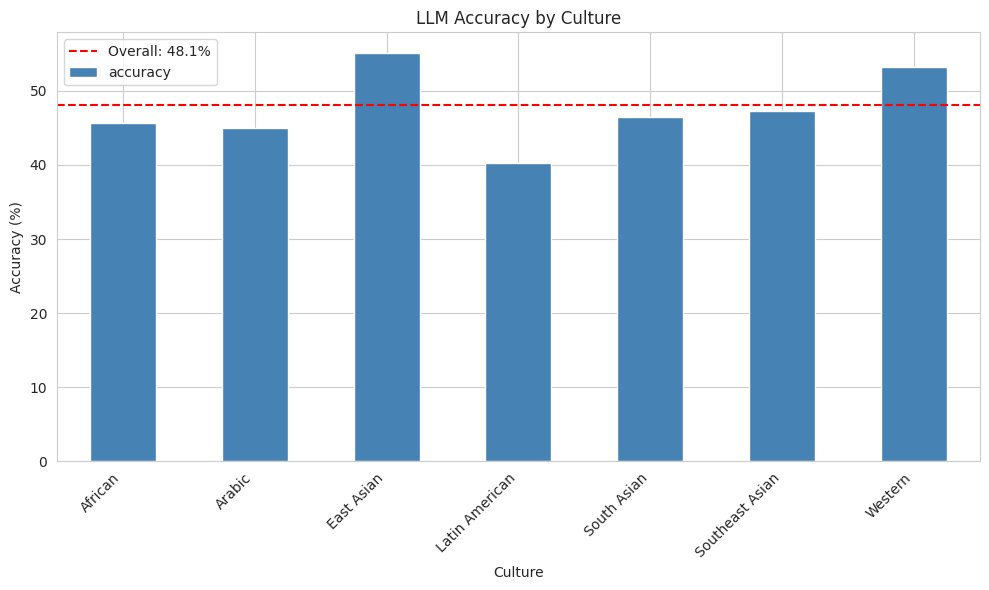

In [17]:
print("="*80)
print("ACCURACY BY CULTURE")
print("="*80)

culture_stats = results_with_meta.groupby('culture').agg({
    'is_correct': ['count', 'sum', 'mean'],
    'confidence': 'mean',
    'correct_prob': 'mean'
}).round(4)

culture_stats.columns = ['total', 'correct', 'accuracy', 'avg_confidence', 'avg_correct_prob']
culture_stats['accuracy'] = culture_stats['accuracy'] * 100

print("\n", culture_stats.to_string())

# Visualize
fig, ax = plt.subplots(figsize=(10, 6))
culture_stats['accuracy'].plot(kind='bar', ax=ax, color='steelblue')
ax.set_ylabel('Accuracy (%)')
ax.set_xlabel('Culture')
ax.set_title('LLM Accuracy by Culture')
ax.axhline(y=accuracy, color='red', linestyle='--', label=f'Overall: {accuracy:.1f}%')
ax.legend()
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

## 13. Culture × Language Heatmap

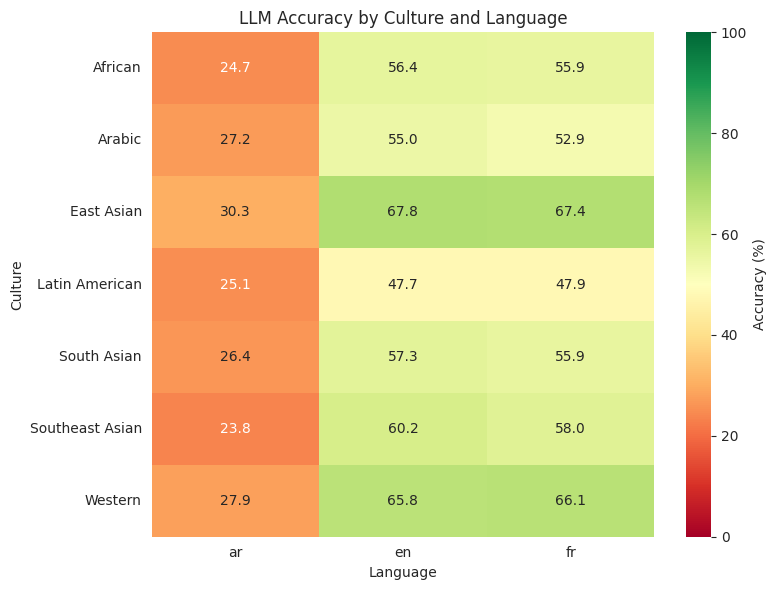


Accuracy Matrix (Culture × Language):
language                ar         en         fr
culture                                         
African          24.674395  56.433376  55.903821
Arabic           27.167474  54.954227  52.872016
East Asian       30.257161  67.765299  67.399089
Latin American   25.113269  47.663430  47.941748
South Asian      26.409592  57.323396  55.865198
Southeast Asian  23.788865  60.231381  57.989877
Western          27.920133  65.773710  66.117582


In [18]:
# Create pivot table: culture × language
culture_lang_accuracy = results_with_meta.pivot_table(
    values='is_correct',
    index='culture',
    columns='language',
    aggfunc='mean'
) * 100

# Heatmap
fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(
    culture_lang_accuracy,
    annot=True,
    fmt='.1f',
    cmap='RdYlGn',
    vmin=0,
    vmax=100,
    ax=ax,
    cbar_kws={'label': 'Accuracy (%)'}
)
ax.set_title('LLM Accuracy by Culture and Language')
ax.set_xlabel('Language')
ax.set_ylabel('Culture')
plt.tight_layout()
plt.show()

print("\nAccuracy Matrix (Culture × Language):")
print(culture_lang_accuracy.to_string())

## 14. Confidence Distribution by Culture

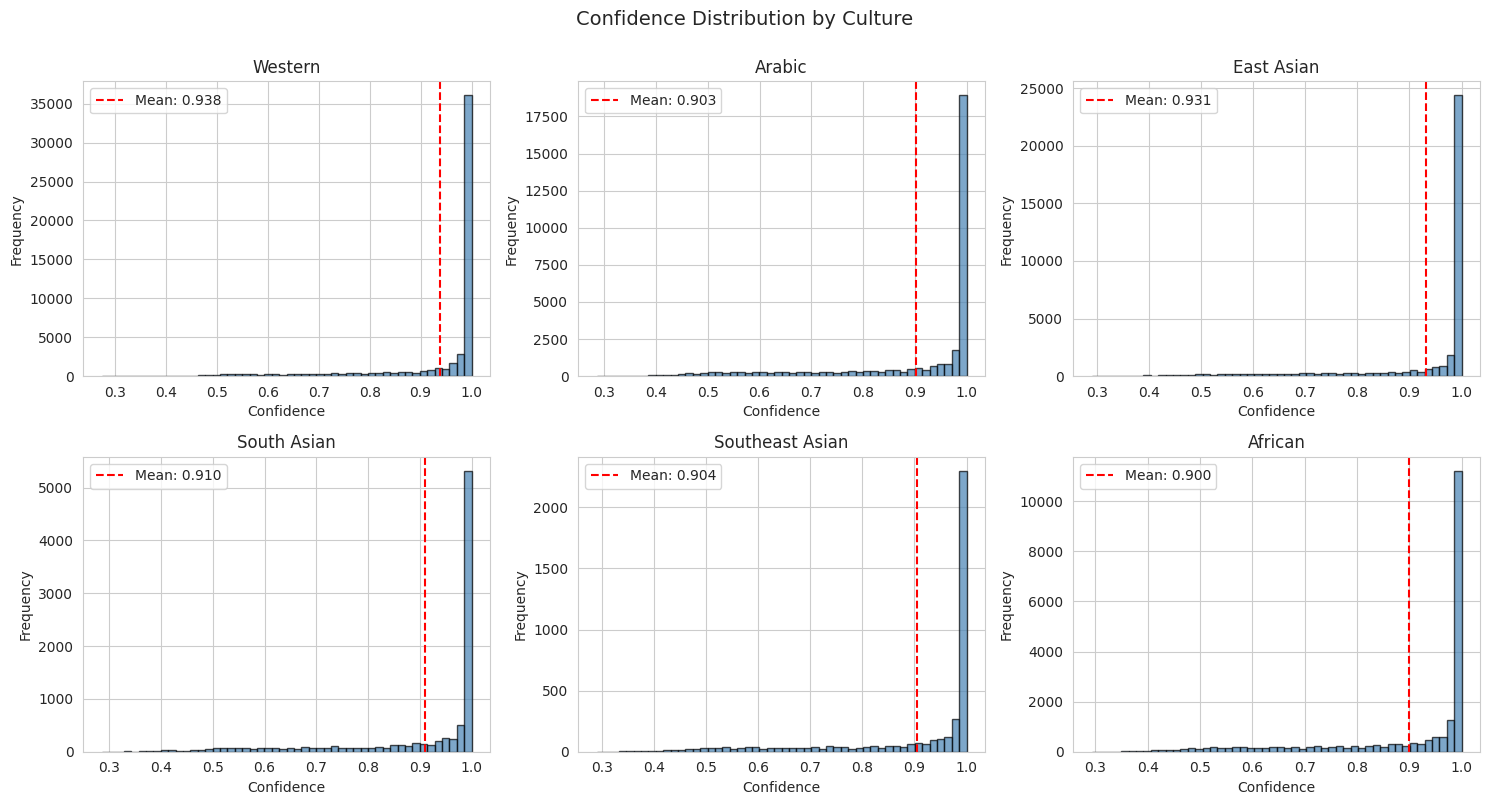

In [19]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
axes = axes.flatten()

cultures = results_with_meta['culture'].unique()
for i, culture in enumerate(cultures):
    if i < len(axes):
        culture_data = results_with_meta[results_with_meta['culture'] == culture]
        axes[i].hist(culture_data['confidence'], bins=50, alpha=0.7, color='steelblue', edgecolor='black')
        axes[i].axvline(
            culture_data['confidence'].mean(),
            color='red',
            linestyle='--',
            label=f'Mean: {culture_data["confidence"].mean():.3f}'
        )
        axes[i].set_title(f'{culture}')
        axes[i].set_xlabel('Confidence')
        axes[i].set_ylabel('Frequency')
        axes[i].legend()

# Hide unused subplots
for i in range(len(cultures), len(axes)):
    axes[i].axis('off')

plt.suptitle('Confidence Distribution by Culture', fontsize=14, y=1.00)
plt.tight_layout()
plt.show()

## 15. Calibration Plot

/tmp/ipykernel_399123/938273539.py:6: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  calibration = results_df.groupby('confidence_bin').agg({


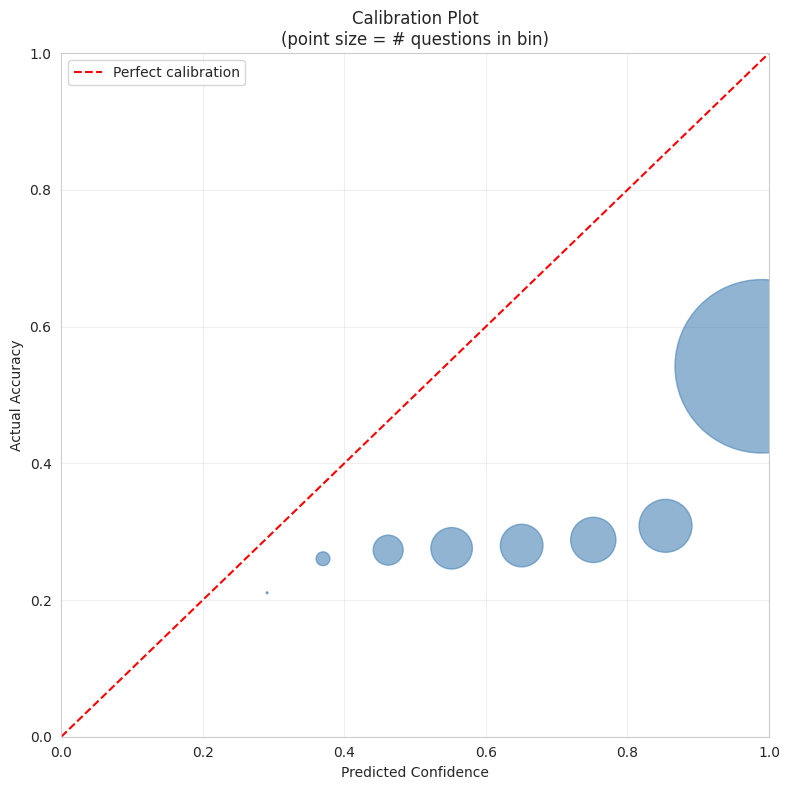

Calibration by confidence bin:
                accuracy   count  avg_confidence
confidence_bin                                  
(0.2, 0.3]      0.210526      19        0.290810
(0.3, 0.4]      0.260343     991        0.369799
(0.4, 0.5]      0.272961    4660        0.461920
(0.5, 0.6]      0.275626    8907        0.551577
(0.6, 0.7]      0.279635    9423        0.650530
(0.7, 0.8]      0.287934   10617        0.751723
(0.8, 0.9]      0.308519   14508        0.853837
(0.9, 1.0]      0.541895  155973        0.989763


In [20]:
# Bin predictions by confidence
bins = np.linspace(0, 1, 11)  # 10 bins
results_df['confidence_bin'] = pd.cut(results_df['confidence'], bins=bins)

# Calculate accuracy per bin
calibration = results_df.groupby('confidence_bin').agg({
    'is_correct': ['mean', 'count'],
    'confidence': 'mean'
})
calibration.columns = ['accuracy', 'count', 'avg_confidence']
calibration = calibration[calibration['count'] > 0]

# Plot
fig, ax = plt.subplots(figsize=(8, 8))
ax.scatter(
    calibration['avg_confidence'],
    calibration['accuracy'],
    s=calibration['count']/10,
    alpha=0.6,
    color='steelblue'
)
ax.plot([0, 1], [0, 1], 'r--', label='Perfect calibration')
ax.set_xlabel('Predicted Confidence')
ax.set_ylabel('Actual Accuracy')
ax.set_title('Calibration Plot\n(point size = # questions in bin)')
ax.legend()
ax.grid(True, alpha=0.3)
ax.set_xlim(0, 1)
ax.set_ylim(0, 1)
plt.tight_layout()
plt.show()

print("Calibration by confidence bin:")
print(calibration.to_string())

## 16. Error Analysis: Most Confused Questions

In [21]:
# Find incorrect predictions with high confidence
incorrect = results_with_meta[~results_with_meta['is_correct']].copy()
incorrect = incorrect.sort_values('confidence', ascending=False)

print("="*80)
print("TOP 10 MOST CONFIDENT ERRORS")
print("="*80)

for i, row in incorrect.head(10).iterrows():
    print(f"\nQuestion {row['question_id']}:")
    print(f"  Entity: {row['wikidata_id']} ({row['culture']}/{row['country']})")
    print(f"  Type: {row['question_type']} | Language: {row['language']}")
    print(f"  Correct: {row['correct_answer']} | Predicted: {row['predicted_answer']}")
    print(f"  Confidence: {row['confidence']:.4f}")
    probs = row['probabilities']
    print(f"  Probabilities: A={probs['A']:.3f}, B={probs['B']:.3f}, C={probs['C']:.3f}, D={probs['D']:.3f}")

TOP 10 MOST CONFIDENT ERRORS

Question 459843:
  Entity: Q6524166 (Latin American/Chile)
  Type: nationality | Language: fr
  Correct: D | Predicted: A
  Confidence: 1.0000
  Probabilities: A=1.000, B=0.000, C=0.000, D=0.000

Question 459840:
  Entity: Q6524166 (Latin American/Chile)
  Type: birth_place | Language: fr
  Correct: C | Predicted: A
  Confidence: 1.0000
  Probabilities: A=1.000, B=0.000, C=0.000, D=0.000

Question 459835:
  Entity: Q18127720 (Latin American/Chile)
  Type: nationality | Language: ar
  Correct: C | Predicted: A
  Confidence: 1.0000
  Probabilities: A=1.000, B=0.001, C=0.000, D=0.000

Question 459825:
  Entity: Q2634554 (Latin American/Chile)
  Type: nationality | Language: fr
  Correct: B | Predicted: C
  Confidence: 1.0000
  Probabilities: A=0.000, B=0.000, C=1.000, D=0.000

Question 459824:
  Entity: Q2634554 (Latin American/Chile)
  Type: nationality | Language: en
  Correct: B | Predicted: C
  Confidence: 1.0000
  Probabilities: A=0.000, B=0.000, C=1.000

## 17. Export Summary Statistics

In [22]:
# Create summary CSV
summary_path = Path('../data/experiment/llm_evaluation_summary.csv')

# Aggregate by culture, language, question_type
summary_df = results_with_meta.groupby(['culture', 'language', 'question_type']).agg({
    'is_correct': ['count', 'sum', 'mean'],
    'confidence': 'mean',
    'correct_prob': 'mean'
}).reset_index()

summary_df.columns = ['culture', 'language', 'question_type', 'total', 'correct', 'accuracy', 'avg_confidence', 'avg_correct_prob']
summary_df['accuracy'] = summary_df['accuracy'] * 100

summary_df.to_csv(summary_path, index=False)

print(f"✓ Saved summary statistics to: {summary_path}")
print(f"\nSummary preview:")
print(summary_df.head(20).to_string(index=False))

✓ Saved summary statistics to: ../data/experiment/llm_evaluation_summary.csv

Summary preview:
   culture language question_type  total  correct  accuracy  avg_confidence  avg_correct_prob
   African       ar    birth_date   2329      537 23.057106        0.928976          0.233474
   African       ar   birth_place   2329      587 25.203950        0.878278          0.256163
   African       ar   nationality   2329      600 25.762130        0.855844          0.259429
   African       en    birth_date   2329      752 32.288536        0.887332          0.319354
   African       en   birth_place   2329     1491 64.018892        0.922141          0.636361
   African       en   nationality   2329     1700 72.992701        0.922522          0.730136
   African       fr    birth_date   2329      696 29.884070        0.847983          0.299656
   African       fr   birth_place   2329     1494 64.147703        0.901992          0.634091
   African       fr   nationality   2329     1716 73.679691

## 18. Final Summary

In [23]:
print("="*80)
print("LLM EVALUATION COMPLETE")
print("="*80)

print(f"\nModel: {MODEL_NAME}")
print(f"Total questions evaluated: {len(results_df):,}")
print(f"Overall accuracy: {accuracy:.2f}%")
print(f"Average confidence: {results_df['confidence'].mean():.4f}")
print(f"Calibration error: {calibration_error:.4f}")

print(f"\nFiles created:")
print(f"  - {RESULTS_PATH} (detailed results, {len(results_df):,} lines)")
print(f"  - {summary_path} (summary statistics)")
print(f"  - {CHECKPOINT_PATH} (checkpoint for resume)")

print(f"\nKey findings:")
print(f"  - Best performing culture: {culture_stats['accuracy'].idxmax()} ({culture_stats['accuracy'].max():.1f}%)")
print(f"  - Worst performing culture: {culture_stats['accuracy'].idxmin()} ({culture_stats['accuracy'].min():.1f}%)")
print(f"  - Best language: {results_df.groupby('language')['is_correct'].mean().idxmax()}")
print(f"  - Best question type: {results_df.groupby('question_type')['is_correct'].mean().idxmax()}")

print("\n" + "="*80)
print("READY FOR GROUPING LOSS ANALYSIS (Next notebook)")
print("="*80)

LLM EVALUATION COMPLETE

Model: mistralai/Mistral-7B-Instruct-v0.2
Total questions evaluated: 205,098
Overall accuracy: 48.11%
Average confidence: 0.9182
Calibration error: 0.4370

Files created:
  - ../data/experiment/llm_results.jsonl (detailed results, 205,098 lines)
  - ../data/experiment/llm_evaluation_summary.csv (summary statistics)
  - ../data/experiment/llm_checkpoint.json (checkpoint for resume)

Key findings:
  - Best performing culture: East Asian (55.1%)
  - Worst performing culture: Latin American (40.2%)
  - Best language: en
  - Best question type: nationality

READY FOR GROUPING LOSS ANALYSIS (Next notebook)
